# Module 2 · Partie 7 : Synthèse, pipeline généralisé et aide-mémoire

Ce dernier notebook **rassemble tout le module 2** (validation, ACP, PCR, PLS). On y revoit les idées clés, puis on transforme les scripts du cours en **fonctions réutilisables** qu'on applique à deux jeux de données différents. On termine par un aide-mémoire, une liste de pièges et un quiz de révision.

**Objectifs**
- Avoir une vue d'ensemble du module : quel problème motive chaque méthode ?
- Disposer d'un formulaire complet (indicateurs de validation, ACP, PCR, PLS, distances).
- Savoir écrire un **pipeline générique** de calibration spectrale : contrôle des spectres (GH) → modèles PCR, PLS et pénalisés en validation croisée → choix du nombre de composantes → validation externe.
- Se préparer à l'examen (*open course* sans LM, 4 h, script + rapport).

**Prérequis** : parties 0 à 6 du module 2, et le module 1.

**Sommaire**
1. Vue d'ensemble du module
2. Formulaire
3. Pipeline généralisé (fonctions réutilisables)
4. Application 1 : acides gras saturés du lait (MIR)
5. Application 2 : azote total des sols (NIR)
6. Aide-mémoire des fonctions R
7. Pièges fréquents
8. Quiz de révision
9. Préparer l'examen

In [1]:
suppressPackageStartupMessages({
  library(pls)       # pcr, plsr, RMSEP, R2, cvsegments
  library(glmnet)    # cv.glmnet
  library(knitr)     # kable
})
options(repr.plot.width = 10, repr.plot.height = 6)

## 7.1 Vue d'ensemble du module

Le module 1 s'arrêtait sur deux constats : un modèle évalué sur ses propres données de calibration paraît toujours meilleur qu'il ne l'est (**surapprentissage**), et les spectres posent des problèmes de **colinéarité** et de **dimension** ($p > n$). Le module 2 répond à ces deux problèmes.

| Problème | Réponse du module 2 | Partie |
|---|---|---|
| Les performances de calibration sont trop optimistes | **Validation** : jeu de validation indépendant (externe) ou **validation croisée** (interne : LOO, k-fold) | 1 |
| Combien de variables / de composantes garder ? | Courbes R² et RMSE de calibration vs validation croisée ; min RMSECV, écart de robustesse, gain de précision, Q² | 1, 3, 4 |
| Spectres atypiques (erreurs de mesure, échantillons hors population) | **ACP** + distance de **Mahalanobis** standardisée (**GH**) ; T² de Hotelling | 2, 4 |
| Colinéarité, $p > n$ | **PCR** : régression sur des composantes principales orthogonales | 3 |
| La PCR résume X sans regarder y | **PLS** : variables latentes qui maximisent la covariance avec y (NIPALS) | 4 |
| Quel modèle choisir ? | Comparaison PCR / PLS / Ridge / Lasso / Elastic Net sur un **jeu de validation externe** | 5 |
| Un nouvel échantillon est-il prédictible ? | **Potentiel de prédiction** : GH du nouvel échantillon projeté dans l'ACP de calibration | 2 |

> **Complément** : le fil rouge du module est la **séparation stricte** entre ce qui sert à construire le modèle (calibration, choix du nombre de composantes, nettoyage) et ce qui sert à l'évaluer (jeu de test). Toute information du jeu de test utilisée pendant la construction rend l'évaluation optimiste.

## 7.2 Formulaire

### Indicateurs de performance
Pour $n$ observations de référence $y_i$ et leurs prédictions $\hat y_i$ (calibration, validation croisée ou test) :

| Indicateur | Formule | Remarque |
|---|---|---|
| $R^2$ | $\mathrm{cor}(y, \hat y)^2$ (ou $1 - \frac{\sum (y_i-\hat y_i)^2}{\sum (y_i-\bar y)^2}$) | Les deux définitions coïncident en calibration, pas forcément en validation |
| RMSE | $\sqrt{\frac{1}{n}\sum (y_i-\hat y_i)^2}$ | RMSEC (calibration), RMSECV (validation croisée), RMSEP (prédiction / test) |
| Biais | $\frac{1}{n}\sum (\hat y_i - y_i)$ | Erreur systématique |
| SEP | $\sqrt{\frac{1}{n-1}\sum (\hat y_i - y_i - \text{biais})^2}$ | Écart-type des erreurs corrigé du biais : $RMSEP^2 \approx SEP^2 + \text{biais}^2$ |
| RPD | $s_y / RMSE$ | Plus il est grand, mieux c'est (rapport entre la dispersion de y et l'erreur) |
| $Q^2_h$ | $1 - PRESS_h / RSS_{h-1}$ | On garde la composante *h* tant que $Q^2_h \ge 1 - 0.95^2 = 0.0975$ |

> **Attention** : au module 1, « SEP » désignait l'écart-type résiduel du modèle `lm` ($\sqrt{SCE/ddl}$). En chimiométrie (scripts et littérature spectrale), SEP désigne l'écart-type des erreurs de prédiction corrigé du biais. Précise toujours la définition utilisée dans un rapport.

### ACP (composantes principales)
$$z_{i1} = u_{11}x_{i1} + u_{21}x_{i2} + \dots + u_{p1}x_{ip}, \qquad \sum_j u_{j1}^2 = 1, \qquad \mathrm{Var}(z_1) \text{ maximale}, \qquad \sum_j u_{jk}u_{jl} = 0 \ (k \ne l)$$
Les $u$ sont les **vecteurs propres** de la matrice de corrélation, les variances des composantes sont les **valeurs propres**.

### PCR (3 phases)
1. ACP sur X centré réduit → scores $Z_k$ (k premières composantes).
2. Régression linéaire $y = Z_k\gamma + e$ (composantes orthogonales : plus de colinéarité).
3. Retour aux variables d'origine : $\beta = U_k\,\gamma$ (puis division par l'écart-type de chaque variable si X a été réduit).

### PLS1 (NIPALS)
1. Standardiser X et y.
2. $w_j = \dfrac{R(x_j, y)}{\sqrt{\sum_j R^2(x_j,y)}}$ ; $t_1 = X w$.
3. Régresser y et chaque $x_j$ sur $t_1$ (moindres carrés : $\beta = (t_1't_1)^{-1}t_1'D$), calculer les résidus (déflation), recommencer sur les résidus pour $t_2, t_3, \dots$

### Distances
$$D_i^2 = (x_i - \mu)^T S^{-1}(x_i - \mu) \ \text{(sur les scores ACP)}, \qquad GH_i = \frac{D_i^2}{n_{CP}} \quad (<3 : \text{OK} ; >5 : \text{outlier})$$
$$T_i^2 = \frac{n}{n-1}\sum_{h=1}^H \frac{t_{hi}^2}{s_h^2}, \qquad \text{atypique si } T_i^2 \ge \frac{H(n^2-1)}{n(n-H)}F_{0.95}(H, n-H)$$

## 7.3 Pipeline généralisé : des scripts aux fonctions

Les scripts du module (`pca_`, `pcr_`, `pls_fatty_acids.R`, `homework2.R`, les deux corrections officielles) répètent les mêmes étapes avec des indices et des noms écrits en dur. On les encapsule dans des fonctions qui prennent une **matrice de spectres `X`** et un **vecteur `y`**, quel que soit le fichier d'origine.

### Étape 1 : performances d'un jeu de prédictions

In [2]:
# Indicateurs de validation d'un vecteur de prédictions
perf_pred <- function(y, pred) {
  e <- pred - y
  c(n = length(y), R2 = cor(y, pred)^2, RMSE = sqrt(mean(e^2)),
    biais = mean(e), SEP = sd(e), RPD = sd(y) / sqrt(mean(e^2)))
}

> **Fonction R** : `sd(e)` divise par $n-1$ et centre sur la moyenne des erreurs : c'est exactement le SEP corrigé du biais.

### Étape 2 : spectres atypiques (ACP + GH)

On utilise `prcomp()` (base R) plutôt que `FactoMineR::PCA()` : les scores sont les mêmes (au signe près), et `predict()` projette directement de nouveaux spectres dans l'ACP de calibration, ce qui donne le **potentiel de prédiction** d'un nouvel échantillon.

In [3]:
# ACP de calibration + distance GH ; nCP = nb de CP pour atteindre 'var_cible' de variance cumulée
ajuster_GH <- function(X, var_cible = 0.99) {
  acp  <- prcomp(X, center = TRUE, scale. = TRUE)
  cum  <- cumsum(acp$sdev^2) / sum(acp$sdev^2)
  nCP  <- which(cum >= var_cible)[1]
  sc   <- acp$x[, 1:nCP, drop = FALSE]
  centre <- colMeans(sc); covar <- cov(sc)
  GH <- mahalanobis(sc, center = centre, cov = covar) / nCP   # mahalanobis() renvoie D²
  list(acp = acp, nCP = nCP, centre = centre, covar = covar, GH = GH)
}

# GH de nouveaux spectres projetés dans l'ACP de calibration (potentiel de prédiction)
GH_nouveaux <- function(modele_GH, Xnew) {
  sc <- predict(modele_GH$acp, newdata = Xnew)[, 1:modele_GH$nCP, drop = FALSE]
  mahalanobis(sc, center = modele_GH$centre, cov = modele_GH$covar) / modele_GH$nCP
}

### Étape 3 : PCR / PLS en validation croisée et choix du nombre de composantes

La fonction renvoie, pour chaque nombre de composantes, les R² et RMSE de calibration et de validation croisée, ainsi que les deux indicateurs de la correction officielle : l'écart de **robustesse** (R² cal − R² CV) et le **gain de précision** (gain de R² CV par rapport au modèle à une composante de moins). Elle propose deux choix : le minimum du RMSECV et le choix plus parcimonieux de `selectNcomp(method = "onesigma")`.

In [4]:
# methode = "pls" ou "pcr" ; segments = liste d'indices (pour comparer les méthodes sur les mêmes segments)
ajuster_composantes <- function(X, y, methode = "pls", ncomp = 30, segments = NULL, seed = 1001) {
  d <- data.frame(y = y); d$X <- X                     # matrice stockée dans une colonne du data.frame
  if (is.null(segments)) { set.seed(seed); segments <- cvsegments(nrow(X), 10) }
  fit <- if (methode == "pls") {
    plsr(y ~ X, data = d, ncomp = ncomp, scale = TRUE, validation = "CV", segments = segments)
  } else {
    pcr(y ~ X, data = d, ncomp = ncomp, scale = TRUE, validation = "CV", segments = segments)
  }
  r2  <- R2(fit, estimate = c("train", "CV"))$val[, 1, -1]      # on retire "(Intercept)"
  rms <- RMSEP(fit, estimate = c("train", "CV"))$val[, 1, -1]
  tab <- data.frame(ncomp = 1:ncomp, R2_cal = r2[1, ], R2_cv = r2[2, ],
                    RMSE_cal = rms[1, ], RMSE_cv = rms[2, ],
                    robustesse = r2[1, ] - r2[2, ], gain_precision = c(NA, diff(r2[2, ])))
  list(modele = fit, table = tab, segments = segments,
       n_min = unname(which.min(rms[2, ])),
       n_onesigma = selectNcomp(fit, method = "onesigma"))
}

### Étape 4 : comparaison des modèles sur un jeu de test

In [5]:
# Compare PCR, PLS (au nb de composantes choisi) et Ridge / Lasso / EN (lambda.1se) sur un jeu de test
comparer_sur_test <- function(fit_pcr, k_pcr, fit_pls, k_pls, X, y, Xtest, ytest, seed = 1001) {
  preds <- list(
    PCR = predict(fit_pcr, newdata = list(X = Xtest), ncomp = k_pcr)[, 1, 1],
    PLS = predict(fit_pls, newdata = list(X = Xtest), ncomp = k_pls)[, 1, 1])
  for (a in c(Ridge = 0, ElasticNet = 0.5, Lasso = 1)) {
    set.seed(seed)
    cvfit <- cv.glmnet(X, y, alpha = a, family = "gaussian")
    nom <- names(which(c(Ridge = 0, ElasticNet = 0.5, Lasso = 1) == a))
    preds[[nom]] <- as.vector(predict(cvfit, newx = Xtest, s = "lambda.1se"))
  }
  t(sapply(preds, perf_pred, y = ytest))
}

> **Attention** : `predict()` d'un modèle `pls` renvoie un **tableau à 3 dimensions** (observations × réponses × nombre de composantes). Avec `ncomp = k`, on garde la seule tranche utile avec `[, 1, 1]`. Et comme le modèle a été construit avec la formule `y ~ X`, `newdata` doit contenir une matrice appelée `X` : `list(X = Xtest)`.

## 7.4 Application 1 : acides gras saturés du lait (spectres MIR)

Calibration sur `fatty_acids.csv` (485 laits), test sur `validation_fatty_acids.csv` (338 laits indépendants), comme dans l'exercice dirigé officiel.

In [6]:
fa  <- read.table("../fatty_acids.csv", sep = ";", header = TRUE)
val <- read.table("../validation_fatty_acids.csv", sep = ";", header = TRUE)
X_fa <- as.matrix(fa[, 5:1064]);  y_fa <- fa$SAT
X_va <- as.matrix(val[, 3:1062]); y_va <- val$SAT
colnames(X_va) <- colnames(X_fa)          # mêmes noms de colonnes en calibration et en test
c(calibration = nrow(X_fa), test = nrow(X_va))

calibration        test 
        485         338

In [7]:
gh_fa <- ajuster_GH(X_fa, var_cible = 0.99)
c(nCP = gh_fa$nCP, GH_sup_3 = sum(gh_fa$GH > 3), GH_sup_5 = sum(gh_fa$GH > 5))
gh_test <- GH_nouveaux(gh_fa, X_va)
c(test_GH_sup_3 = sum(gh_test > 3), test_GH_sup_5 = sum(gh_test > 5))

nCP GH_sup_3 GH_sup_5 
      48        3        0

test_GH_sup_3 test_GH_sup_5 
            2             1

Il faut **48 composantes** pour dépasser strictement 99 % de variance cumulée. Le Rmd officiel en retient **47**, qui donnent environ 99 % : la différence vient seulement de la façon d'arrondir le seuil, et elle change très peu les GH. Le GH des 338 laits de validation, projetés dans l'ACP de calibration, indique combien d'entre eux sortent de la variabilité couverte par le modèle.

In [8]:
garder <- gh_fa$GH < 3
Xc <- X_fa[garder, ]; yc <- y_fa[garder]
set.seed(1001); seg <- cvsegments(nrow(Xc), 10)       # mêmes segments pour PCR et PLS
res_pcr <- ajuster_composantes(Xc, yc, "pcr", ncomp = 30, segments = seg)
res_pls <- ajuster_composantes(Xc, yc, "pls", ncomp = 30, segments = seg)
c(PCR_min = res_pcr$n_min, PCR_onesigma = res_pcr$n_onesigma,
  PLS_min = res_pls$n_min, PLS_onesigma = res_pls$n_onesigma)
kable(res_pls$table[1:15, ], digits = 3)

PCR_min PCR_onesigma      PLS_min PLS_onesigma 
          27           21           30           27



|         | ncomp| R2_cal| R2_cv| RMSE_cal| RMSE_cv| robustesse| gain_precision|
|:--------|-----:|------:|-----:|--------:|-------:|----------:|--------------:|
|1 comps  |     1|  0.877| 0.873|    0.299|   0.304|      0.004|             NA|
|2 comps  |     2|  0.906| 0.904|    0.262|   0.264|      0.002|          0.031|
|3 comps  |     3|  0.917| 0.914|    0.245|   0.250|      0.004|          0.010|
|4 comps  |     4|  0.934| 0.928|    0.219|   0.229|      0.006|          0.014|
|5 comps  |     5|  0.944| 0.938|    0.201|   0.213|      0.006|          0.010|
|6 comps  |     6|  0.953| 0.945|    0.185|   0.199|      0.008|          0.008|
|7 comps  |     7|  0.961| 0.952|    0.169|   0.188|      0.009|          0.006|
|8 comps  |     8|  0.965| 0.956|    0.159|   0.180|      0.010|          0.004|
|9 comps  |     9|  0.970| 0.960|    0.147|   0.170|      0.010|          0.004|
|10 comps |    10|  0.972| 0.962|    0.142|   0.166|      0.010|          0.002|
|11 comps |    11|  0.974|

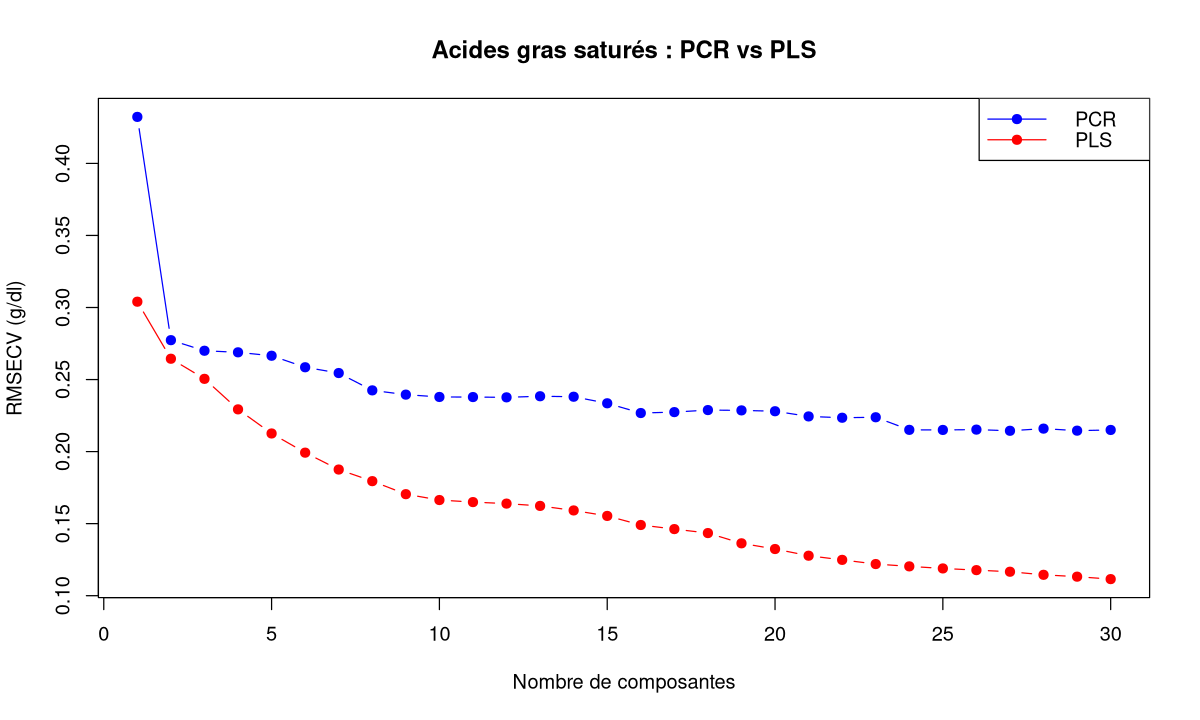

In [9]:
plot(res_pcr$table$RMSE_cv, type = "b", pch = 19, col = "blue",
     ylim = range(res_pcr$table$RMSE_cv, res_pls$table$RMSE_cv),
     xlab = "Nombre de composantes", ylab = "RMSECV (g/dl)", main = "Acides gras saturés : PCR vs PLS")
lines(res_pls$table$RMSE_cv, type = "b", pch = 19, col = "red")
legend("topright", legend = c("PCR", "PLS"), col = c("blue", "red"), lty = 1, pch = 19)

La PLS atteint une erreur de validation croisée donnée avec **moins de composantes** que la PCR, parce que ses variables latentes sont construites en tenant compte de y.

> **Attention** : ici le RMSECV de la PLS diminue encore à 30 composantes (le maximum testé, pour limiter le temps de calcul). La correction officielle va jusqu'à 70 composantes et retient 11 variables latentes avec la règle du « gain de précision » : au-delà, chaque composante n'apporte presque plus rien au R² de CV (colonne `gain_precision` du tableau). Le minimum strict du RMSECV conduit souvent à un nombre de composantes très élevé ; c'est pour cela qu'on lui préfère une règle parcimonieuse.

In [10]:
k_pcr <- res_pcr$n_onesigma; k_pls <- res_pls$n_onesigma
tab_fa <- comparer_sur_test(res_pcr$modele, k_pcr, res_pls$modele, k_pls, Xc, yc, X_va, y_va)
kable(tab_fa, digits = 4)



|           |   n|     R2|   RMSE|   biais|    SEP|    RPD|
|:----------|---:|------:|------:|-------:|------:|------:|
|PCR        | 338| 0.8509| 0.3319| -0.1393| 0.3017| 2.2600|
|PLS        | 338| 0.9580| 0.2361|  0.1557| 0.1777| 3.1772|
|Ridge      | 338| 0.8486| 0.3392| -0.1381| 0.3102| 2.2113|
|ElasticNet | 338| 0.8822| 0.2887| -0.1100| 0.2673| 2.5979|
|Lasso      | 338| 0.8881| 0.2886| -0.1205| 0.2626| 2.5990|

## 7.5 Application 2 : azote total des sols (spectres NIR)

Même pipeline, **autre technologie (NIR), autre matrice (sol), autre variable**. Seules les lignes de lecture changent. Les zéros de `Ycal` et `Ytest` sont des valeurs manquantes.

In [11]:
Xcal <- as.matrix(read.table("../Xcal.txt", sep = ";", header = TRUE))
Ycal <- read.table("../Ycal.txt", sep = ";")
Xtst <- as.matrix(read.table("../Xtest.txt", sep = ";", header = TRUE))
Ytst <- read.table("../Ytest.txt", sep = ";")
ok  <- Ycal[, 1] > 0; okt <- Ytst[, 1] > 0
X_so <- Xcal[ok, ];  y_so <- Ycal[ok, 1]
X_st <- Xtst[okt, ]; y_st <- Ytst[okt, 1]
c(calibration = nrow(X_so), test = nrow(X_st))

calibration        test 
        485         160

In [12]:
gh_so <- ajuster_GH(X_so, var_cible = 0.999)
c(nCP = gh_so$nCP, GH_sup_3 = sum(gh_so$GH > 3), GH_sup_5 = sum(gh_so$GH > 5))

nCP GH_sup_3 GH_sup_5 
       4       40       16

Les spectres de sols sont si corrélés que 99 % de la variabilité est atteinte avec 2 composantes seulement : on vise donc 99.9 %, comme dans `homework2.R` (la correction officielle va jusqu'à 99.99 %). Le TP (partie 6) a montré que les échantillons à GH élevé sont surtout les sols **les plus riches en azote** : ce ne sont pas des erreurs mais le haut de la gamme à prédire. On les **garde** ici.

In [13]:
set.seed(1001); seg_so <- cvsegments(nrow(X_so), 10)
so_pcr <- ajuster_composantes(X_so, y_so, "pcr", ncomp = 30, segments = seg_so)
so_pls <- ajuster_composantes(X_so, y_so, "pls", ncomp = 30, segments = seg_so)
c(PCR_min = so_pcr$n_min, PCR_onesigma = so_pcr$n_onesigma,
  PLS_min = so_pls$n_min, PLS_onesigma = so_pls$n_onesigma)

PCR_min PCR_onesigma      PLS_min PLS_onesigma 
          13           11           16           10

In [14]:
tab_so <- comparer_sur_test(so_pcr$modele, so_pcr$n_min, so_pls$modele, so_pls$n_min,
                            X_so, y_so, X_st, y_st)
kable(tab_so, digits = 4)



|           |   n|     R2|   RMSE|   biais|    SEP|    RPD|
|:----------|---:|------:|------:|-------:|------:|------:|
|PCR        | 160| 0.6771| 0.7310| -0.0127| 0.7332| 1.7414|
|PLS        | 160| 0.6823| 0.7219| -0.0223| 0.7238| 1.7635|
|Ridge      | 160| 0.3915| 1.0318|  0.0448| 1.0341| 1.2337|
|ElasticNet | 160| 0.5104| 0.9009|  0.0739| 0.9007| 1.4130|
|Lasso      | 160| 0.5144| 0.8959|  0.0743| 0.8957| 1.4209|

> **Attention** : le Ridge paraît ici très mauvais en partie pour une raison technique. Pour le Ridge, la grille de λ choisie automatiquement par `cv.glmnet` s'arrête trop tôt : le minimum de l'erreur de CV tombe au bord de la grille, et `lambda.1se` est alors trop pénalisant. Avec une grille étendue vers les petits λ (argument `lambda = `), le Ridge s'améliore nettement (voir la partie 1). Vérifie toujours que `lambda.min` n'est pas la plus petite valeur testée.

Pour situer ces chiffres, la Table 1 de l'article *Chimiométrie 2006* donne pour Nt un RMSEP de **0.84** (PLS des auteurs), **0.59** (LOCAL), **0.56** (LS-SVM) et 0.65 / 0.77 / 0.97 pour les trois participants.

### Exercice 7.1 : choisir le nombre de composantes autrement
Pour les sols, compare sur le jeu de test la PLS à `so_pls$n_min` composantes et la PLS à `so_pls$n_onesigma` composantes. Le choix le plus parcimonieux est-il beaucoup moins bon ?

In [15]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
p_min <- predict(so_pls$modele, newdata = list(X = X_st), ncomp = so_pls$n_min)[, 1, 1]
p_1se <- predict(so_pls$modele, newdata = list(X = X_st), ncomp = so_pls$n_onesigma)[, 1, 1]
kable(rbind(min_RMSECV = perf_pred(y_st, p_min), onesigma = perf_pred(y_st, p_1se)), digits = 4)
```

La règle « onesigma » choisit le plus petit nombre de composantes dont le RMSECV ne dépasse pas le minimum de plus d'un écart-type. Le modèle est plus simple, donc en principe plus robuste. Sur le jeu de test, la perte de précision est en général faible : c'est le compromis parcimonie / précision discuté aux parties 3 et 4.

</details>

### Exercice 7.2 : potentiel de prédiction du jeu de test des sols
Avec `ajuster_GH()` et `GH_nouveaux()`, calcule le GH des 160 sols de test projetés dans l'ACP de calibration. Combien dépassent 3 ? Leurs erreurs de prédiction PLS sont-elles plus grandes que celles des autres ?

In [16]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
gh_st <- GH_nouveaux(gh_so, X_st)
p <- predict(so_pls$modele, newdata = list(X = X_st), ncomp = so_pls$n_min)[, 1, 1]
err <- abs(p - y_st)
c(GH_sup_3 = sum(gh_st > 3))
tapply(err, gh_st > 3, median)     # erreur absolue médiane : GH <= 3 (FALSE) vs GH > 3 (TRUE)
```

Les échantillons hors de la variabilité de calibration (GH > 3) sont ceux pour lesquels le modèle extrapole : leurs erreurs sont typiquement plus grandes. C'est exactement l'usage du GH décrit au §3.5 du syllabus : **avant de faire confiance à une prédiction, on vérifie que le spectre est dans le domaine de calibration**.

</details>

## 7.6 Aide-mémoire des fonctions R du module

| Catégorie | Fonction | Rôle |
|---|---|---|
| **Lecture** | `read.table(f, sep=";", header=TRUE)`, `read.csv(f, sep=";", check.names=FALSE)` | Lire spectres et références |
| | `matplot(x, t(X), type="l", lty=1)` | Tracer tous les spectres |
| **Validation** | `sample()`, `cvsegments(n, k)` | Découper calibration / validation, segments de CV |
| | `validation = "CV"` / `"LOO"`, `segments=` (dans `pcr`, `plsr`) | Validation croisée intégrée |
| | `cv.glmnet(x, y, alpha)` → `cvm`, `cvsd`, `lambda.min`, `lambda.1se`, `nzero` | CV des régressions pénalisées |
| **ACP** | `FactoMineR::PCA(X, scale.unit=TRUE, ncp, graph=FALSE)` → `$eig`, `$ind$coord`, `$var$cor` | ACP du cours |
| | `prcomp(X, scale.=TRUE)`, `predict(acp, newdata)`, `eigen(cor(X))` | ACP base R, projection, calcul à la main |
| **Distances** | `mahalanobis(sc, center, cov)` | Renvoie $D^2$ ; GH = $D^2$ / nCP |
| | `qf(0.95, H, n-H)` | Seuil du T² de Hotelling |
| **PCR / PLS** | `pcr(y ~ X, data, ncomp, scale=TRUE, validation)` | Régression sur composantes principales |
| | `plsr(y ~ X, data, ncomp, scale=TRUE, method="oscorespls", validation)` | Régression PLS |
| | `summary()`, `explvar()`, `R2(m, "all")`, `RMSEP(m, "all")` (`$val[estimate, réponse, modèle]`) | Performances par nombre de composantes |
| | `validationplot()`, `predplot()`, `coefplot()`, `scoreplot()`, `loadingplot()` | Graphiques |
| | `selectNcomp(m, method="onesigma"/"randomization")` | Choix parcimonieux du nombre de composantes |
| | `scores()`, `loadings()`, `loading.weights()`, `m$projection`, `Yloadings()` | t, p, w, w*, c |
| | `predict(m, newdata, ncomp)[, 1, 1]`, `coef(m, ncomp)` | Prédictions, coefficients sur les variables d'origine |
| **Graphiques ggplot** | `reshape2::melt()` + `ggplot() + geom_point()` / `geom_tile()` | Style des corrections officielles |
| **Sauvegarde** | `save(best, file=)`, `load()` | Rendre l'équation du homework |

## 7.7 Pièges fréquents

1. **Évaluer sur les données de calibration** : R² et RMSE de calibration s'améliorent toujours avec le nombre de composantes. Seules la validation croisée et le jeu de test disent si le modèle généralise.
2. **La validation croisée n'est pas une validation externe** : avec des données répétées (même vache, même parcelle), un même individu peut se trouver en calibration et en validation. Elle reste une validation **interne**.
3. **`set.seed()`** avant toute CV k-fold : sans lui, les segments changent à chaque exécution, et donc le nombre de composantes choisi aussi. Pour comparer PCR et PLS équitablement, utilise les **mêmes segments** (`cvsegments`).
4. **`mahalanobis()` renvoie la distance au carré** ($D^2$). Le GH du cours se calcule comme $D^2$ / nCP. Le syllabus écrit la formule avec une racine, mais les corrections officielles et les seuils 3 et 5 utilisent $D^2$.
5. **Le GH dépend du nombre de composantes** : 99 % de variance donne 47 CP pour le lait (MIR) mais 2 CP pour les sols (NIR). Choisis et justifie le seuil.
6. **Retirer des outliers avant la CV** rend la CV optimiste (on retire les cas difficiles de l'évaluation). Pour juger honnêtement l'intérêt du retrait, retire-les **dans chaque segment de calibration seulement** (comme dans `homework2.R`).
7. **Un échantillon à GH élevé n'est pas forcément une erreur** : pour les sols, ce sont surtout les teneurs en azote les plus élevées.
8. **`R2()` et `RMSEP()` du package pls** incluent un modèle « (Intercept) » (0 composante) en première position : la composante *k* est en position *k + 1* (`$val[, , k + 1]`), ou on retire la première avec `[, , -1]`.
9. **`predict()` pls** renvoie un tableau 3D ; sans `ncomp`, on obtient les prédictions pour **tous** les nombres de composantes.
10. **Noms de colonnes** : pour prédire un jeu de test avec un modèle construit sur un `data.frame`, les colonnes doivent porter **les mêmes noms** qu'en calibration (la correction officielle les renomme `SPEC1…`).
11. **Valeurs manquantes codées 0** dans `Ycal`/`Ytest` : les retirer avant tout calcul (moyenne, modèle, test).
12. **Le jeu de test ne sert qu'une fois**, à la fin. Le réutiliser pour choisir le nombre de composantes ou λ revient à en faire un jeu de calibration.

## 7.8 Quiz de révision

**Q1.** Quelle est la différence entre validation interne et externe ?

<details>
<summary><b>Voir la réponse</b></summary>

La validation **externe** utilise un jeu de données **indépendant** qui n'a servi ni à construire ni à paramétrer le modèle (ex. `validation_fatty_acids.csv`, `Xtest`). La validation **interne** (validation croisée, jackknife, bootstrap) réutilise le jeu de calibration en le découpant. Elle ne garantit pas l'indépendance, notamment avec des données répétées.

</details>

**Q2.** En validation croisée à 10 segments sur 485 échantillons, combien de modèles sont ajustés ? Et en leave-one-out ?

<details>
<summary><b>Voir la réponse</b></summary>

10 modèles (chacun sur environ 9/10 des données), contre 485 en leave-one-out (un modèle par échantillon retiré). Chaque échantillon reçoit **une** prédiction faite par un modèle qui ne l'a pas vu, et on calcule le R² et le RMSE de CV sur l'ensemble de ces prédictions.

</details>

**Q3.** Pourquoi le R² de calibration augmente-t-il toujours avec le nombre de composantes, alors que le R² de validation croisée finit par diminuer ?

<details>
<summary><b>Voir la réponse</b></summary>

Les dernières composantes modélisent du bruit propre au jeu de calibration (surapprentissage). Ce bruit ne se retrouve pas dans les données non vues, d'où la chute du R² de CV (Fig. 2 du syllabus). On choisit le nombre de composantes avant cette chute.

</details>

**Q4.** Quelles sont les quatre contraintes qui définissent les composantes principales ?

<details>
<summary><b>Voir la réponse</b></summary>

1) Combinaison linéaire des variables centrées réduites ; 2) somme des carrés des coefficients égale à 1 ; 3) variance maximale (décroissante d'une composante à la suivante) ; 4) orthogonalité : somme des produits des coefficients de deux composantes nulle. La contrainte 2 est nécessaire, sinon on pourrait augmenter la variance à volonté en multipliant les coefficients.

</details>

**Q5.** Quel est le principal inconvénient de la PCR, et comment la PLS y répond-elle ?

<details>
<summary><b>Voir la réponse</b></summary>

La PCR construit ses composantes à partir de la seule **variabilité de X**, sans tenir compte de y : une composante très variable mais sans lien avec y peut passer avant une composante peu variable mais prédictive. La PLS construit des variables latentes qui maximisent la **covariance** entre X et y : elle atteint en général la même précision avec moins de composantes.

</details>

**Q6.** Dans NIPALS, comment calcule-t-on les poids $w$ de la première variable latente ?

<details>
<summary><b>Voir la réponse</b></summary>

Sur les données standardisées, on calcule la corrélation de chaque $x_j$ avec y, puis on divise par $\sqrt{\sum_j R^2}$ pour que $\sum w_j^2 = 1$. Pour l'octane : $\sqrt{\sum R^2} = 1.916$ et $w_6 = 0.985/1.916 = 0.514$. Ensuite $t_1 = X_s w$.

</details>

**Q7.** Un échantillon de test a un GH de 6. Que faire de sa prédiction ?

<details>
<summary><b>Voir la réponse</b></summary>

GH > 5 : le spectre est hors de la variabilité de calibration, la prédiction est une extrapolation **non fiable**. Il faut vérifier la mesure (erreur d'acquisition ?) ou, s'il s'agit d'un échantillon réel, enrichir la calibration avec des échantillons similaires.

</details>

**Q8.** Que vaut la limite de Q² et que signifie-t-elle ?

<details>
<summary><b>Voir la réponse</b></summary>

$1 - 0.95^2 = 0.0975$. On garde la composante *h* tant que $Q^2_h = 1 - PRESS_h/RSS_{h-1} \ge 0.0975$, c'est-à-dire tant qu'elle réduit l'erreur de prédiction d'au moins environ 5 % par rapport à l'erreur d'ajustement du modèle précédent.

</details>

**Q9.** Pourquoi la PLS ne nécessite-t-elle pas d'inversion de matrice, et pourquoi est-ce un avantage ?

<details>
<summary><b>Voir la réponse</b></summary>

NIPALS n'enchaîne que des régressions simples sur une composante à la fois ($t't$ est un scalaire). Il n'y a pas de $(X'X)^{-1}$ à calculer : la méthode fonctionne quand $p > n$ ou en cas de forte colinéarité, et reste rapide sur de gros volumes de données.

</details>

**Q10.** `cv.glmnet` renvoie `lambda.min` et `lambda.1se`. Lequel choisir ?

<details>
<summary><b>Voir la réponse</b></summary>

`lambda.min` minimise l'erreur moyenne de CV. `lambda.1se` est le plus grand λ dont l'erreur reste à moins d'un écart-type du minimum : le modèle est plus pénalisé, plus parcimonieux, souvent plus robuste. C'est l'équivalent de `selectNcomp(method = "onesigma")` pour la PLS.

</details>

## 7.9 Préparer l'examen

**Format** : examen *open course* **sans** modèle de langage (4 h), avec une analyse de données à rendre (**script + rapport**).

**Trame de rapport conseillée** pour une analyse de type « module 2 » :

1. **Objectif et données** : variable à prédire (unités), technologie (MIR/NIR), nombre d'échantillons, valeurs manquantes, jeu de test disponible ?
2. **Contrôle de y** : statistiques descriptives, histogramme, transformation éventuelle.
3. **Contrôle des spectres** : tracé, régions bruitées (CV par point), ACP (% de variance, nombre de CP retenu et pourquoi), GH (seuils 3 et 5), décision argumentée sur les outliers.
4. **Modèles** : PCR et PLS en validation croisée (segments fixés), éventuellement Ridge / Lasso / Elastic Net avec `cv.glmnet`.
5. **Choix du nombre de composantes** : courbes R² et RMSE cal/CV, min RMSECV, robustesse, gain de précision, `onesigma`.
6. **Validation externe** : R², RMSEP, biais, SEP, RPD sur le jeu de test ; GH des échantillons de test.
7. **Conclusion** : modèle retenu, performances, limites, pistes (prétraitements SNV/dérivées, plus d'échantillons dans les zones mal couvertes).

> **Complément** : les fonctions de la section 7.3 te font gagner un temps précieux le jour de l'examen. Copie-les avec celles du module 1 dans un fichier `outils_AM2.R` que tu chargeras avec `source("outils_AM2.R")`.

## Récapitulatif

- **Valider** : jamais sur les données de calibration seules ; validation croisée (interne) pour choisir la complexité, jeu de test (externe) pour évaluer.
- **ACP + GH** : détecter les spectres atypiques et vérifier qu'un nouvel échantillon est prédictible.
- **PCR** : ACP puis régression sur les composantes, puis retour aux variables ; résout la colinéarité et le cas $p > n$, mais ignore y lors de la réduction.
- **PLS** : variables latentes construites avec y (NIPALS) ; moins de composantes, interprétation par les poids w*, Q² et T² de Hotelling.
- **Comparer** PCR, PLS et régressions pénalisées sur un jeu de test, avec R², RMSEP, biais, SEP et RPD.

La suite du cours (module 3) passe à une variable à expliquer **qualitative** avec la régression logistique.